# Weather Conditions Associated with High PM2.5 Concentrations in Sofia
### A mathematical analysis of daily observations


## 1. Introduction

### Why I chose this topic

Air quality is something I encounter in everyday life in Sofia. I wanted to understand whether the weather conditions on a particular day are related to the concentration of fine particulate matter (PM2.5) recorded at a monitoring location in Sofia. Rather than trying to predict pollution, I decided to use mathematical concepts from the course to describe patterns in observations that have already been collected.

I selected OpenAQ location 3287527 because it is close to the area where I live. This made the question personally relevant, but it is also an important limitation: one monitoring location cannot represent every neighborhood in Sofia, and the measurements are not a direct estimate of my personal exposure.

### What I want to find out

My main question is:

How are meteorological conditions associated with daily PM2.5 concentrations in Sofia, individually and in combination?

I divided it into two smaller questions:

- RQ1: How is PM2.5 associated with temperature, relative humidity, wind speed and atmospheric pressure when each variable is considered separately?
- RQ2: How do PM2.5 concentrations and the frequency of high-PM2.5 days differ across combinations of relatively lower or higher temperature and wind speed?

For RQ1, I use Pearson correlation to examine the direction and strength of the linear relationship between PM2.5 and each meteorological variable. This allows me to compare the direction and magnitude of the linear associations between PM2.5 and the selected meteorological variables in the observed sample.

For RQ2, I examine temperature and wind speed together by dividing each variable into two groups based on its median. I then compare the four resulting combinations using descriptive statistics and conditional probability. This allows me to compare how concentrations differ between groups and how frequently high-PM2.5 days occur under each combination.

The purpose is to describe patterns in the observed data, rather than predict future pollution levels or establish causal relationships.

### How previous research informs the analysis

Previous research suggests several mechanisms through which weather and the urban environment may affect particulate concentrations. Chen et al. [1] review how meteorological conditions can influence dispersion, transport, formation and removal of PM2.5, with relationships varying by place and period. This cautions me against treating a correlation measured in Sofia as a universal rule.

Petrov et al. [2] examine modelled pollutant dispersion around buildings under different meteorological conditions in Sofia. Their work illustrates why wind and the built environment matter for local dispersion. Their model concerns other pollutants, particularly nitrogen oxides, rather than directly measuring the PM2.5 relationships in my dataset; I use it as physical context, not as confirmation of my coefficients.

Dimitrova et al. [3] place pollution in the context of Bulgarian urban microclimates and local conditions, reminding me that a single monitoring location cannot represent every neighborhood. Evgenieva et al. [4] examine Saharan-dust intrusions over Sofia using particulate measurements, showing that transported particles can also contribute to pollution episodes; the influence is not limited to local emissions.

These studies motivate the choice of weather variables and provide possible explanations, but they cannot establish what the correlations in my observations should be. I calculate those independently and interpret them cautiously.

The analytical sample contains daily observations from 12 September 2025 to 4 November 2026, and the pollution variable in this project is PM2.5 only. Seasonal differences, emissions and other unmeasured factors may affect the observed associations.


## 2. Data Collection and Preparation

To compare daily PM2.5 concentrations with weather conditions on the same local calendar day, I prepared a dataset by combining two data sources. The complete retrieval and preparation workflow is documented in `Appendix_A_Data_Collection.ipynb`.

### Data sources and preparation

I used the OpenAQ API v3 for location 3287527 in Sofia to obtain daily observations for PM2.5, PM10, temperature and relative humidity from the sensors associated with that location. PM10 is retained in the original CSV but is not used in this mathematical analysis. The OpenAQ sensor metadata identify PM2.5 in µg/m³, temperature in °C and relative humidity in %.

I used the Open-Meteo Historical Weather API at 42.7066° N, 23.3025° E, with `timezone=Europe/Sofia`, to obtain hourly wind speed at 10 metres (`wind_speed_10m`, km/h) and surface pressure (`surface_pressure`, hPa). I calculated daily arithmetic means from the hourly series and joined them to the OpenAQ table by local calendar date.

The sources are not equivalent instruments: OpenAQ observations are associated with the selected monitoring location, whereas Open-Meteo provides historical model-based estimates for nearby coordinates. Their values can be compared descriptively, but they need not describe exactly the same physical point.

### Time period and analytical sample

The OpenAQ request began on 1 January 2025, but the first available daily observation in the collected dataset was 2 January 2025. I retained 4 November 2026 as the last date of the original collection period, without adding later observations. The prepared combined CSV therefore contains 595 daily records from 2 January 2025 to 4 November 2026. Appendix A explains the timestamp conversion, the selected date boundaries, and the matching Open-Meteo request period.

For the mathematical analysis, I use the prepared CSV rather than requesting new API responses on each run. I retain records dated 11 September 2025 or later; the first available date after that filter is 12 September 2025, and the last is 4 November 2026. This produces 419 daily observations. I select the five variables needed for the research questions, then check for duplicate dates and missing values. The count describes available observations, not an assumption that every calendar date in the interval is present.

### Data provenance and validation

Appendix A documents the API endpoints and sensor selection, pagination, local-date conversion, daily weather aggregation, merging and CSV export. During development, I also compared the reconstructed historical CSV with the original file: all 595 dates and their values matched within a numerical tolerance of 10⁻⁶, including the 419 dates in this analysis. This comparison was a development check and is not a separate requirement for running the final appendix.

The successful reconstruction supports the consistency of the documented data-preparation process; it does not independently verify the accuracy of the source measurements or the Open-Meteo estimates. Historical API responses can change, and OpenAQ's reported daily coverage was not used to exclude low-coverage observations. These remain relevant limitations when interpreting the results.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Load the combined dataset
DATA_PATH = Path("all_sofia_air_quality_weather_daily.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Combined CSV not found. Place all_sofia_air_quality_weather_daily.csv "
        "in the same folder as this notebook."
    )

print("Reading dataset:", DATA_PATH)
START_DATE = pd.Timestamp("2025-09-11")

raw = pd.read_csv(DATA_PATH)

required = ["Date", "PM2,5", "Temperature", "Humidity", "WindSpeed", "Pressure"]
missing_columns = set(required) - set(raw.columns)

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

# Select variables and prepare the analysis period
df = raw[required].copy().rename(columns={"PM2,5": "PM2.5"})
df["Date"] = pd.to_datetime(df["Date"], errors="raise")
df = df.loc[df["Date"] >= START_DATE].sort_values("Date").reset_index(drop=True)

# Check data quality
print("Rows:", len(df))
print("Observed range:", df["Date"].min().date(), "to", df["Date"].max().date())
print("Duplicate dates:", df["Date"].duplicated().sum())

missing_dates = pd.date_range(df["Date"].min(), df["Date"].max()).difference(df["Date"])
print("Missing calendar dates:", len(missing_dates))
print("Missing values:\n", df.isna().sum())

assert not df["Date"].duplicated().any(), "Duplicate dates need investigation"
assert not df[["PM2.5", "Temperature", "Humidity", "WindSpeed", "Pressure"]].isna().any().any(), "Missing values need investigation"

display(df.head())


Reading dataset: all_sofia_air_quality_weather_daily.csv
Rows: 419
Observed range: 2025-09-12 to 2026-11-04
Duplicate dates: 0
Missing calendar dates: 0
Missing values:
 Date           0
PM2.5          0
Temperature    0
Humidity       0
WindSpeed      0
Pressure       0
dtype: int64


,Date,PM2.5,Temperature,Humidity,WindSpeed,Pressure
0,2025-09-12,4.93,30.2,34.1,5.020833,955.033333
1,2025-09-13,13.90,24.7,43.2,7.912500,958.258333
2,2025-09-14,10.40,22.8,44.4,12.879167,956.704167
3,2025-09-15,8.11,22.4,43.1,5.233333,957.058333
4,2025-09-16,11.40,22.6,37.2,2.975000,955.616667


## 3. Mathematical Foundations

I use descriptive statistics, correlation and empirical conditional probability for two related purposes: to quantify associations between PM2.5 and individual meteorological variables, and to compare PM2.5 across combinations of temperature and wind speed.

### 3.1 Mean, median and standard deviation

For $n$ observations, the arithmetic mean is

$$\bar{x}=\frac{1}{n}\sum_{i=1}^{n}x_i.$$

The mean describes the average level, but a few unusually high PM2.5 observations can raise it. I therefore also examine the median, the middle of the ordered observations, which is less sensitive to extremes. Comparing the mean and median provides an initial indication of possible asymmetry and the influence of unusually high observations on the average.

The sample standard deviation measures dispersion around the mean:

$$s=\sqrt{\frac{1}{n-1}\sum_{i=1}^{n}(x_i-\bar{x})^2}.$$

A larger standard deviation means observations are more widely spread; it does not by itself identify the source of unusually high values. Together, the mean, median and standard deviation describe the central tendency and variability of the observations.

### 3.2 Covariance and Pearson correlation

For RQ1, I ask whether PM2.5 tends to be higher or lower when a meteorological variable is higher or lower. Sample covariance summarizes whether the two variables' deviations from their respective means tend to have the same or opposite signs:

$$\operatorname{Cov}(X,Y)=\frac{1}{n-1}\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y}).$$

Because covariance depends on measurement units, I use Pearson correlation to standardize it:

$$r_{XY}=\frac{\operatorname{Cov}(X,Y)}{s_Xs_Y},\qquad -1\leq r_{XY}\leq1.$$

The sign of the Pearson correlation coefficient indicates the direction of the linear association, while its absolute value indicates the strength of that association. A value near zero does not rule out nonlinear relationships. I calculate the coefficients with `pandas`; they describe associations, not causal effects or changes per unit of weather.

### 3.3 Comparing temperature and wind combinations

For RQ2, I classify temperature and wind speed separately using their sample medians. For this analysis, *Lower* means at or below the sample median and *Higher* means above the sample median. The combinations are Lower/Lower, Lower/Higher, Higher/Lower and Higher/Higher. I compare each group's size, mean, median and standard deviation.

The median split is interpretable but discards information: nearly identical observations can fall on opposite sides of a cutoff, and tied values may produce unequal group sizes. The categories are not physical weather regimes, and their comparison is not a formal test of interaction.

### 3.4 High-PM2.5 days and conditional frequency

I define a high-PM2.5 day as an observation strictly above the sample's 75th percentile:

$$H=\{\mathrm{PM}_{2.5}>Q_{0.75}\}.$$

This is a relative threshold for this dataset, not a regulatory or health-based limit. For a weather group $C$, the observed high-day proportion is

$$\widehat P(H\mid C)=\frac{N(H\cap C)}{N(C)}.$$

I compare this with the overall sample proportion using the relative frequency ratio:

$$R(C)=\frac{\widehat P(H\mid C)}{\widehat P(H)}.$$

Values above 1 indicate high days were proportionally more common in the group than in the full sample. The full sample includes that group, so this is a descriptive baseline comparison, not a relative risk between independent groups. All thresholds and proportions use the same complete analytical sample.


## 4. Getting to Know the Data

Before calculating correlations, I examine the distribution of the daily observations. The numerical summary describes central values and variability; the histogram shows the shape of the PM2.5 distribution; and the time-series plot shows when unusually high concentrations occurred. These checks matter because extreme observations can affect the mean and Pearson correlation.


,PM2.5,Temperature,Humidity,WindSpeed,Pressure
count,419.00,419.00,419.00,419.00,419.00
mean,20.15,16.23,45.68,6.79,953.17
std,16.04,6.37,8.40,3.38,6.16
min,0.85,1.65,27.10,1.66,928.58
25%,10.80,11.30,38.95,4.51,950.69
50%,15.50,15.40,45.40,5.70,954.22
75%,24.25,22.05,52.50,8.63,956.90
max,144.00,30.20,64.30,19.98,968.10


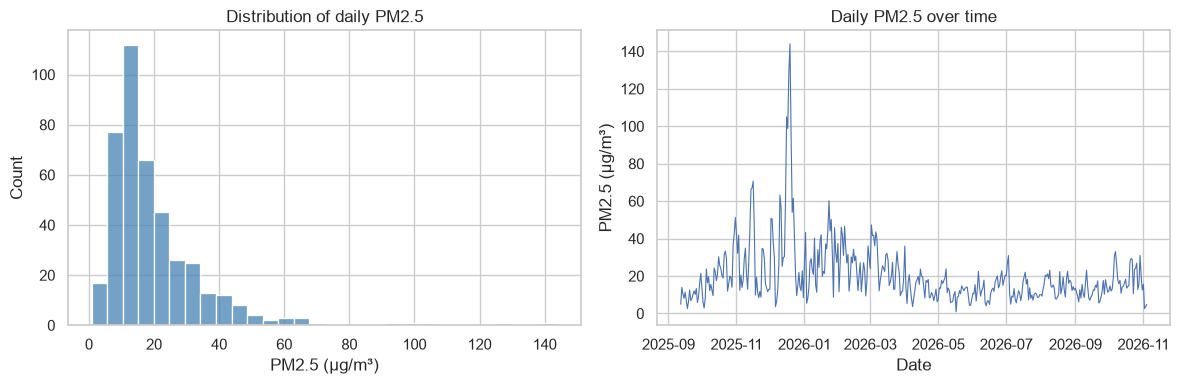

In [2]:
variables = ["PM2.5", "Temperature", "Humidity", "WindSpeed", "Pressure"]
display(df[variables].describe().round(2))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["PM2.5"], bins=30, ax=axes[0], color="steelblue")
axes[0].set_title("Distribution of daily PM2.5")
axes[0].set_xlabel("PM2.5 (µg/m³)")
axes[0].set_ylabel("Count")
axes[1].plot(df["Date"], df["PM2.5"], lw=0.8)
axes[1].set_title("Daily PM2.5 over time")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("PM2.5 (µg/m³)")
fig.tight_layout()
plt.show()

### Interpreting the descriptive statistics and plots

Daily PM2.5 has a mean of 20.15 µg/m³, a median of 15.50 µg/m³, and a standard deviation of 16.04 µg/m³. The mean exceeds the median, which is consistent with the right-skewed distribution visible in the histogram. Relatively high observations contribute to the mean being above the median. The observed PM2.5 values range from 0.85 to 144.00 µg/m³, indicating substantial variation between days.

The time series shows a pronounced cluster of high values on 16–20 December 2025, including the maximum of 144.00 µg/m³ on 19 December. These values occur on consecutive days rather than as one isolated observation. The plot alone, however, cannot determine whether this pattern is related to temperature, seasonality, emissions, or other factors.

This distribution influences my later analytical choices: I interpret Pearson correlations with care, compare group medians as well as means, and perform a sensitivity check excluding PM2.5 observations above the 99th percentile.

## 5. RQ1 — Looking at Each Weather Variable Separately

My first research question examines the linear associations of daily PM2.5 with temperature, relative humidity, wind speed and atmospheric pressure. I calculate Pearson's r for each variable and present scatter plots alongside the coefficient table. The plots help me assess the spread of the observations, the approximate form of the relationships, and the presence of unusually high PM2.5 values that may influence the correlations. These are unadjusted descriptive correlations; they do not control for seasonality or demonstrate causation.


,variable,pearson_r,n
0,Temperature,-0.348,419
1,Humidity,0.197,419
2,WindSpeed,-0.289,419
3,Pressure,0.027,419


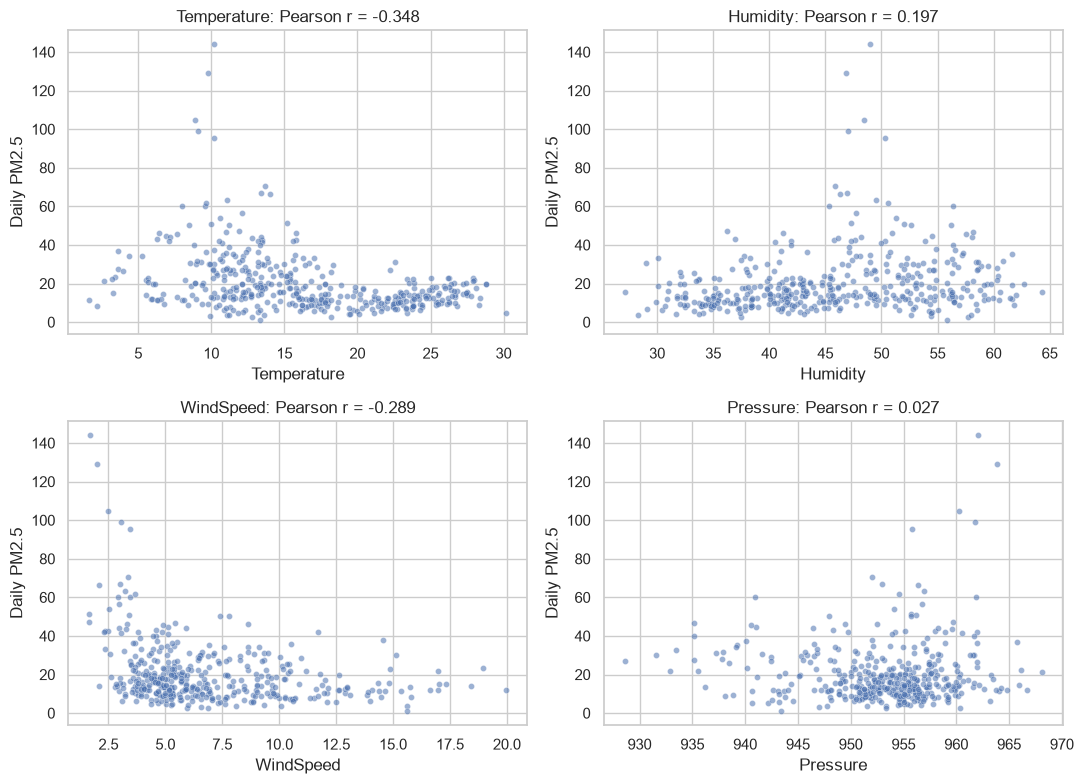

In [3]:
weather_vars = ["Temperature", "Humidity", "WindSpeed", "Pressure"]
rq1 = pd.DataFrame({
    "variable": weather_vars,
    "pearson_r": [df[["PM2.5", col]].corr().iloc[0, 1] for col in weather_vars],
    "n": [df[["PM2.5", col]].dropna().shape[0] for col in weather_vars],
})
rq1["absolute_r"] = rq1["pearson_r"].abs()
display(rq1[["variable", "pearson_r", "n"]].round(3))

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, col in zip(axes.flat, weather_vars):
    sns.scatterplot(data=df, x=col, y="PM2.5", ax=ax, s=19, alpha=0.55)
    r = df[["PM2.5", col]].corr().iloc[0, 1]
    ax.set_title(f"{col}: Pearson r = {r:.3f}")
    ax.set_ylabel("Daily PM2.5")
fig.tight_layout()
plt.show()

### Interpreting the correlations

Across the 419 complete daily observations, temperature has the largest absolute Pearson correlation with PM2.5 (r ≈ −0.348), followed by wind speed (r ≈ −0.289). Higher temperature and stronger wind tend to coincide with lower PM2.5, although the scatter plots show substantial variability. These coefficients summarize overall linear tendencies in the sample and do not predict PM2.5 concentrations on individual days.

Relative humidity has a smaller positive correlation (r ≈ +0.197). Atmospheric pressure has a correlation near zero (r ≈ +0.027), indicating little overall linear association in the full sample; this does not rule out more complex relationships.

The scatter plots show considerable dispersion and several unusually high PM2.5 observations. The negative wind-speed correlation is compatible with atmospheric dispersion as a possible explanation, but the scatter plots and correlation coefficients cannot establish the underlying physical mechanism. Likewise, the temperature association may reflect the heating season and other seasonal differences.

Temperature and wind speed therefore provide a useful pair for the joint descriptive comparison in RQ2 because they have the two largest absolute Pearson correlations among the four meteorological variables, not because the correlations establish causal importance.

### Checking the influence of extreme PM2.5 observations

Because the PM2.5 distribution contains unusually high values, I recalculate the four Pearson coefficients after excluding observations above the sample's 99th percentile. This removes five days. I do not regard these observations as errors and retain them in the main analysis. This is a targeted sensitivity check, not a test of general stability or statistical significance.


In [4]:
rq1_cutoff = df["PM2.5"].quantile(0.99)
rq1_trimmed = df.loc[df["PM2.5"] <= rq1_cutoff]
comparison_rq1 = rq1[["variable", "pearson_r", "n"]].copy()
comparison_rq1 = comparison_rq1.rename(columns={"pearson_r": "original_r", "n": "original_n"})
comparison_rq1["r_without_top_1pct_pm25"] = [
    rq1_trimmed[["PM2.5", col]].corr().iloc[0, 1] for col in weather_vars
]
comparison_rq1["trimmed_n"] = [
    rq1_trimmed[["PM2.5", col]].dropna().shape[0] for col in weather_vars
]
comparison_rq1["change_in_r"] = comparison_rq1["r_without_top_1pct_pm25"] - comparison_rq1["original_r"]
print(f"PM2.5 99th percentile: {rq1_cutoff:.2f}")
print(f"Days excluded in sensitivity check: {len(df) - len(rq1_trimmed)}")
display(comparison_rq1.round(3))
print("Largest absolute change in Pearson r:", round(comparison_rq1["change_in_r"].abs().max(), 3))
print("Sign changes:", ((comparison_rq1["original_r"] * comparison_rq1["r_without_top_1pct_pm25"]) < 0).sum())


PM2.5 99th percentile: 91.02
Days excluded in sensitivity check: 5


,variable,original_r,original_n,r_without_top_1pct_pm25,trimmed_n,change_in_r
0,Temperature,-0.348,419,-0.369,414,-0.020
1,Humidity,0.197,419,0.233,414,0.036
2,WindSpeed,-0.289,419,-0.265,414,0.024
3,Pressure,0.027,419,-0.086,414,-0.114


Largest absolute change in Pearson r: 0.114
Sign changes: 1


### Interpreting the sensitivity check and answering RQ1

With the five highest PM2.5 days excluded (n = 414), the temperature correlation changes from −0.348 to −0.369, wind speed from −0.289 to −0.265, and humidity from +0.197 to +0.233. These three associations keep their direction and change modestly, suggesting that the five extreme days do not entirely drive the patterns.

Pressure changes from +0.027 to −0.086. This is the largest absolute coefficient change (about 0.114) and the only sign reversal, but both coefficients remain close to zero; I would not interpret it as a substantive reversal.

**Answer to RQ1:** Temperature and wind speed have the two largest absolute Pearson correlations with PM2.5 in the sample, both in the negative direction. Relative humidity has a smaller positive correlation, while atmospheric pressure has little overall linear association with PM2.5. The sensitivity check suggests that the main temperature, wind-speed and humidity patterns are not driven solely by the five highest PM2.5 observations. These relationships remain descriptive and unadjusted for seasonality, emissions and other potential confounding factors.


## 6. RQ2 — What Happens When Temperature and Wind Are Considered Together?

RQ1 examined the weather variables separately. For RQ2, I compare four temperature–wind combinations formed using the two sample medians. I calculate each group's size, mean, median and standard deviation of PM2.5, along with the proportion exceeding the sample's 75th-percentile threshold.

I want to compare PM2.5 concentrations across the four combinations and identify where high-PM2.5 days occur most frequently. The categories are relative to this sample; they do not represent fixed meteorological boundaries or prove an interaction between weather variables.


In [ ]:
analysis = df[["Date", "PM2.5", "Temperature", "WindSpeed"]].dropna().copy()
t_median = analysis["Temperature"].median()
w_median = analysis["WindSpeed"].median()
analysis["Temperature group"] = np.where(analysis["Temperature"] <= t_median, "Lower", "Higher")
analysis["Wind group"] = np.where(analysis["WindSpeed"] <= w_median, "Lower", "Higher")
q75 = analysis["PM2.5"].quantile(0.75)
analysis["High PM2.5"] = analysis["PM2.5"] > q75
baseline = analysis["High PM2.5"].mean()

summary = (analysis.groupby(["Temperature group", "Wind group"])
           .agg(n=("PM2.5", "size"), mean_pm25=("PM2.5", "mean"),
                median_pm25=("PM2.5", "median"), std_pm25=("PM2.5", "std"),
                high_days=("High PM2.5", "sum"), high_day_proportion=("High PM2.5", "mean")))
summary["relative_frequency_ratio"] = summary["high_day_proportion"] / baseline
summary = summary.reindex(pd.MultiIndex.from_product(
    [["Lower", "Higher"], ["Lower", "Higher"]], names=["Temperature group", "Wind group"]))
print(f"Temperature median: {t_median:.2f} °C")
print(f"Wind-speed median: {w_median:.2f} km/h")
print(f"High-PM2.5 threshold (strictly above): {q75:.2f} µg/m³")
print(f"Baseline P(H): {baseline:.3f} ({analysis['High PM2.5'].sum()} / {len(analysis)})")
assert summary["n"].sum() == len(analysis)
assert summary["n"].min() > 0
# Directly show numerator/denominator and the baseline comparison.
summary["high_day_fraction"] = summary["high_days"].astype(int).astype(str) + "/" + summary["n"].astype(int).astype(str)
print("\nGroup sizes and observed high-day counts:")
display(summary[["n", "mean_pm25", "median_pm25", "std_pm25", "high_day_fraction", "high_day_proportion", "relative_frequency_ratio"]].round(3))


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
mean_matrix = summary["mean_pm25"].unstack("Wind group").loc[["Lower", "Higher"], ["Lower", "Higher"]]
prob_matrix = (summary["high_day_proportion"] * 100).unstack("Wind group").loc[["Lower", "Higher"], ["Lower", "Higher"]]
count_matrix = summary["n"].unstack("Wind group").loc[["Lower", "Higher"], ["Lower", "Higher"]]
mean_labels = mean_matrix.copy().astype(str)
prob_labels = prob_matrix.copy().astype(str)
for r in mean_matrix.index:
    for c in mean_matrix.columns:
        mean_labels.loc[r, c] = f"{mean_matrix.loc[r, c]:.1f}\nn={count_matrix.loc[r, c]}"
        prob_labels.loc[r, c] = f"{prob_matrix.loc[r, c]:.1f}%\nn={count_matrix.loc[r, c]}"
sns.heatmap(mean_matrix, annot=mean_labels, fmt="", cmap="Blues", ax=axes[0], cbar_kws={"label": "Mean PM2.5 (µg/m³)"})
axes[0].set_title("Mean PM2.5 by condition")
sns.heatmap(prob_matrix, annot=prob_labels, fmt="", cmap="Oranges", ax=axes[1], cbar_kws={"label": "High-day frequency (%)"})
axes[1].set_title("High-PM2.5 days (%) by condition")
for ax in axes:
    ax.set_xlabel("Wind speed group")
    ax.set_ylabel("Temperature group")
fig.tight_layout()
plt.show()
print("Highest mean group:", summary["mean_pm25"].idxmax())
print("Highest high-day frequency group:", summary["high_day_proportion"].idxmax())


### Interpreting the four temperature–wind combinations

The lower-temperature / lower-wind group has the highest mean PM2.5 (37.22 µg/m³) and median (31.55 µg/m³) across 82 days. Its standard deviation is also the largest (approximately 25.42 µg/m³), so individual days still vary considerably. The elevated median suggests that the higher PM2.5 level in this group is not attributable only to a handful of exceptional observations.

The intermediate groups are informative: lower temperature / higher wind has a mean of 19.17 µg/m³ across 129 days, whereas higher temperature / lower wind has a mean of 15.62 µg/m³ across 128 days. The higher temperature / higher wind group has the lowest mean (11.49 µg/m³) and median (10.45 µg/m³) across 80 days.

Within lower-temperature days, the mean differs more between lower and higher wind (37.22 versus 19.17 µg/m³) than it does within higher-temperature days (15.62 versus 11.49 µg/m³). This is an interesting descriptive contrast, not a formal test of interaction.

### How frequently do high-PM2.5 days occur?

The high-PM2.5 threshold is strictly above 24.25 µg/m³. Across the sample, 105 of 419 days (25.1%) exceed it. In the lower-temperature / lower-wind group, 53 of 82 days (64.6%) exceed it, approximately 2.58 times the full-sample frequency.

The other groups have 37/129 (28.7%) high-PM2.5 days for lower temperature / higher wind, 12/128 (9.4%) for higher temperature / lower wind, and 3/80 (3.8%) for higher temperature / higher wind. The contrast is therefore evident in both typical concentrations and the frequency of relatively high observations.

These are observed proportions, not future probabilities or causal risks. In particular, the 2.58 ratio compares a group with a baseline that includes that same group.


### Checking whether extreme observations change the group comparison

Because the lower-temperature / lower-wind group has the highest mean and the greatest variability, I repeat the group-mean comparison after excluding the five observations above the overall 99th percentile of PM2.5. The original days remain in the main analysis. I also inspect group sizes: each contains at least 80 observations, although this does not by itself guarantee statistical precision.


In [ ]:
cutoff_99 = analysis["PM2.5"].quantile(0.99)
trimmed = analysis.loc[analysis["PM2.5"] <= cutoff_99]
trimmed_means = (trimmed.groupby(["Temperature group", "Wind group"])["PM2.5"]
                 .mean().reindex(summary.index))
comparison = pd.DataFrame({"original_mean": summary["mean_pm25"],
                           "mean_excluding_top_1pct": trimmed_means,
                           "original_median": summary["median_pm25"],
                           "original_n": summary["n"],
                           "trimmed_n": trimmed.groupby(["Temperature group", "Wind group"]).size().reindex(summary.index, fill_value=0)})
print(f"\n99th-percentile PM2.5 cutoff: {cutoff_99:.2f} µg/m³")
print(f"Observations excluded in sensitivity check: {len(analysis)-len(trimmed)}")
display(comparison.round(2))
print("Highest mean after sensitivity check:", trimmed_means.idxmax())
assert summary["n"].min() > 0, "At least one condition group is empty."


### Interpreting the sensitivity check and answering RQ2

After excluding the five observations above the PM2.5 99th percentile for this sensitivity check, the lower-temperature / lower-wind group's mean decreases from 37.22 to approximately 32.20, but it remains the highest. All five excluded observations belong to that group; the other three group means do not change in this particular check.

This shows that the five extreme days contribute to, but do not fully explain, the highest group mean. It does not address sensitivity to the median cutoffs, seasonality or unmeasured emissions, and it is not a statistical significance test.

**Answer to RQ2:** The relatively lower-temperature / lower-wind group has the highest mean and median PM2.5 concentrations and the largest observed proportion of high-PM2.5 days in this sample. The relatively higher-temperature / higher-wind group has the lowest values on these measures. The intermediate groups also differ, but these comparisons do not establish independent causal effects of temperature or wind speed and do not constitute a formal test of interaction.


## 7. Seasonal Robustness Check

The overall correlations may partly reflect seasonal differences. For example, colder periods may coincide with higher PM2.5 concentrations because of heating emissions and other seasonal factors.

To explore this limitation, I calculate Pearson correlations between PM2.5 and temperature, and between PM2.5 and wind speed, separately within each meteorological season.

This is an exploratory robustness check. It does not fully control for seasonality or other confounding factors, and it does not establish causation.


In [8]:
# Use the same 419 observations as RQ2; do not reload the CSV.
seasonal_df = analysis.copy()
assert len(seasonal_df) == 419
assert seasonal_df["Date"].nunique() == 419

season_names = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Autumn", 10: "Autumn", 11: "Autumn",
}
seasonal_df["Season"] = seasonal_df["Date"].dt.month.map(season_names)

results = [{
    "Period": "Overall",
    "Days": len(seasonal_df),
    "PM2.5 vs Temperature": seasonal_df["PM2.5"].corr(seasonal_df["Temperature"]),
    "PM2.5 vs WindSpeed": seasonal_df["PM2.5"].corr(seasonal_df["WindSpeed"]),
}]

for season in ["Winter", "Spring", "Summer", "Autumn"]:
    subset = seasonal_df.loc[seasonal_df["Season"] == season]
    results.append({
        "Period": season,
        "Days": len(subset),
        "PM2.5 vs Temperature": subset["PM2.5"].corr(subset["Temperature"]),
        "PM2.5 vs WindSpeed": subset["PM2.5"].corr(subset["WindSpeed"]),
    })

seasonal_results = pd.DataFrame(results)
display(seasonal_results.round(3))


,Period,Days,PM2.5 vs Temperature,PM2.5 vs WindSpeed
0,Overall,419,-0.348,-0.289
1,Winter,90,0.170,-0.532
2,Spring,92,-0.314,-0.396
3,Summer,92,0.444,-0.172
4,Autumn,145,-0.240,-0.379


### Interpreting the seasonal check

The overall negative temperature correlation (r = −0.348) is not consistent across seasons. It is negative in spring (−0.314) and autumn (−0.240), but positive in winter (+0.170) and summer (+0.444). This suggests that the overall association may partly reflect differences between seasons and should not be interpreted as a uniform within-season relationship.

The wind-speed correlation remains negative in all four seasons, ranging from −0.172 in summer to −0.532 in winter. This is more consistent with the overall negative wind-speed association (r = −0.289), although the magnitude varies by season.

The analytical period spans slightly more than one year, with unequal numbers of observations across seasons. These descriptive correlations do not control for other factors or establish causation.


## 8. Discussion and Limitations

### Putting the two research questions together

The two analyses reveal broadly related descriptive patterns, although they examine the same observations in different ways. RQ1 finds negative linear correlations for temperature (r ≈ −0.348) and wind speed (r ≈ −0.289). RQ2 finds the highest mean (37.22 µg/m³), median (31.55 µg/m³) and high-PM2.5-day proportion (64.6%) when both variables are lower, compared with 3.8% high days when both are higher.

The intermediate groups show that the difference between wind categories is more pronounced within the lower-temperature category than within the higher-temperature category. This is a descriptive contrast, not a demonstrated statistical interaction. RQ2 helps make the correlations interpretable as group comparisons, but it is not independent confirmation of RQ1.

### What these results cannot tell me

#### Analytical limitations

Seasonality and confounding remain major limitations. Colder periods may coincide with heating emissions and different atmospheric conditions, so the overall negative temperature correlation cannot be attributed to temperature alone. I explored this issue by calculating Pearson correlations within each season. The temperature correlation changed direction across seasons, whereas the wind-speed correlation remained negative in all four seasons. However, this descriptive comparison does not fully account for seasonal influences, and emission sources and other potential confounding factors were not measured.

The seasonal groups contain unequal numbers of observations (winter: 90, spring: 92, summer: 92, autumn: 145). Consecutive daily observations may also be temporally dependent. These within-season correlations should therefore be interpreted cautiously rather than as stable seasonal relationships.

The median splits simplify continuous variables, discarding differences within groups and assigning nearly identical observations to opposite categories around a cutoff. The four-group analysis is exploratory rather than a formal interaction test.

#### Data limitations

OpenAQ values are associated with one monitoring location, selected because it is near where I live, and cannot represent every Sofia neighborhood or my personal exposure. Wind speed and pressure are Open-Meteo historical model-based estimates for nearby coordinates, not observations from the same instrument. The sensor and weather API metadata provide the reported units, and the documented workflow reproduced the original 595-row CSV within a numerical tolerance of 10⁻⁶. This confirms consistency of the prepared data, not the independent accuracy of the underlying measurements. OpenAQ daily coverage was not used to filter observations, and historical API data may be revised.

#### Temporal and interpretive limitations

Daily aggregation hides shorter pollution peaks and within-day wind changes. Consecutive high days may belong to one extended episode, so 419 daily records are not necessarily 419 independent atmospheric events. The sample-based 75th-percentile threshold defines relatively high PM2.5 observations within this dataset; it is not a regulatory or health-based threshold. The conditional proportions are descriptive, not future probabilities or causal risks.

### How the results relate to published research

The negative wind association is compatible with the general importance of atmospheric dispersion discussed by Chen et al. [1]. Petrov et al. [2] illustrate the influence of meteorological conditions and buildings on modelled dispersion in Sofia, but their pollutant focus differs from my PM2.5 data. Neither source establishes the mechanism behind my numerical correlation.

The temperature association requires particular caution because, as Chen et al. [1] discuss, meteorology–PM2.5 relationships depend on multiple processes and local conditions. Dimitrova et al. [3] place pollution in the context of Bulgarian urban microclimates, supporting the limitation of conclusions to one location. Evgenieva et al. [4] document Saharan-dust intrusions over Sofia, an example of transported particulate pollution not fully captured by my four weather variables.

The literature makes the patterns physically plausible and identifies alternative influences; it does not demonstrate what caused the associations in this sample. Overall, the results describe this dataset rather than a general physical law, prediction model or causal relationship.

## 9. Conclusion

I investigated how daily PM2.5 at a monitoring location in Sofia is associated with meteorological conditions using descriptive statistics, Pearson correlation and empirical conditional probability.

For RQ1, temperature (r ≈ −0.348) and wind speed (r ≈ −0.289) have the two largest absolute Pearson correlations with PM2.5 among the four weather variables in the full sample, both negative. Relative humidity has a smaller positive correlation (r ≈ +0.197), while atmospheric pressure has little overall linear association (r ≈ +0.027). These coefficients summarize overall linear tendencies in the sample; they do not, by themselves, predict or explain PM2.5 concentrations on individual days.

For RQ2, the relatively lower-temperature / lower-wind group has the highest mean (37.22 µg/m³), median (31.55 µg/m³) and observed proportion of high-PM2.5 days (53/82, or 64.6%). The relatively higher-temperature / higher-wind group has the lowest mean and median and only 3/80 high-PM2.5 days (3.8%). The intermediate groups lie between these extremes. The high-PM2.5 threshold is strictly above 24.25 µg/m³, defined from this sample's 75th percentile rather than a regulatory or health standard.

In the targeted sensitivity check excluding the five PM2.5 observations above the 99th percentile, the temperature, wind-speed and humidity correlations retain their directions, and the relatively lower-temperature / lower-wind group still has the highest mean PM2.5 (32.20 µg/m³ after exclusion). This reduces concern that a few extreme observations entirely determine these descriptive patterns, but it does not resolve other sources of uncertainty.

The seasonal robustness check adds an important qualification to RQ1. The temperature correlation changes direction across seasons, suggesting that the overall negative association may partly reflect seasonal differences rather than a uniform within-season relationship. In contrast, the wind-speed correlation remains negative in all four seasons, although its magnitude varies. The seasonal groups are unequal and this descriptive check does not fully account for confounding factors.

Overall, temperature and wind speed show observed descriptive associations with PM2.5, but the seasonal analysis shows that the two associations should not be interpreted in the same way. The project identifies and compares patterns without establishing their causes or constructing a prediction model. Useful next steps would be to assess observation coverage more systematically, extend the observation period across several complete annual cycles, and examine seasonal patterns using longer and more evenly balanced seasonal samples.

## References and Documentation

### Scientific literature

[1] Chen, Z., Chen, D., Zhao, C., et al. (2020). Influence of meteorological conditions on PM2.5 concentrations across China: A review of methodology and mechanism. *Environment International, 139*, 105558. https://doi.org/10.1016/j.envint.2020.105558

[2] Petrov, A., Georgieva, E., & Hristova, E. (2024). Sensitivity Analysis of Modelled Air Pollutant Distribution around Buildings under Different Meteorological Conditions. *Atmosphere, 15*(6), 638. https://doi.org/10.3390/atmos15060638

[3] Dimitrova, R., Georgiev, S., Dzhambov, A. M., Ivanov, V., Panev, T., & Georgieva, T. (2026). Study of the Relationship Between Urban Microclimate, Air Pollution, and Human Health in the Three Biggest Cities in Bulgaria. *Urban Science, 10*(2), 69. https://doi.org/10.3390/urbansci10020069

[4] Evgenieva, T., Vakareeva, E., Gurdev, L., & Dreischuh, T. (2024). Identification of Saharan-Dust Intrusions over Sofia, Bulgaria, Using Near-Ground PM10 and PM2.5 Mass Concentration Measurements. *Aerosol and Air Quality Research, 24*, 230304. https://doi.org/10.4209/aaqr.230304

*Note:* Reference [4] includes both particle fractions, but this project analyzes PM2.5 only. The article is cited solely for its findings on particulate transport and the local Sofia context; no PM10 data enter the calculations.

### Software and libraries

- NumPy Developers. *NumPy documentation*. https://numpy.org/doc/stable/
- pandas Development Team. *pandas documentation*. https://pandas.pydata.org/docs/
- Matplotlib Development Team. *Matplotlib documentation*. https://matplotlib.org/stable/
- seaborn Developers. *seaborn documentation*. https://seaborn.pydata.org/

### Data sources and preparation

- OpenAQ. *OpenAQ API v3*, location ID 3287527 and daily sensor observations. https://docs.openaq.org/ and https://api.openaq.org/v3/locations/3287527
- Open-Meteo. *Historical Weather API*, hourly `wind_speed_10m` and `surface_pressure` for 42.7066° N, 23.3025° E, `Europe/Sofia`. https://open-meteo.com/en/docs/historical-weather-api
- Appendix A: Data Collection and Preparation (`Appendix_A_Data_Collection.ipynb`) documents the API retrieval, daily aggregation, date handling, merging, validation and CSV export, based on the original `data_extract.ipynb` and `wind_info.ipynb` workflows.

Data validation: The API metadata identify the reported units, and the reconstruction was compared with the original combined CSV during development. All 595 historical dates and their values agreed within a tolerance of 10⁻⁶. This is a reproducibility check, not an independent audit of source accuracy.